# Entrenamiento colaborativo: factorización matricial

Este notebook entrena el primer modelo de ratings explícitos Goodreads. Sigue una metodología PyTorch por épocas: mini-batches, MSE, Adam, validación independiente, Early Stopping, curvas y checkpoint del mejor `state_dict`. No usa CNN, contenido, ratings cero ni matrices densas.

La preparación temporal usa `date_added`: es fecha de incorporación, no de lectura. Por eso el protocolo es inicial y debe reevaluarse antes de experimentos definitivos.

In [1]:
from pathlib import Path
import json, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Markdown
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'ml').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from ml.collaborative import MatrixFactorization, rating_metrics
from ml.recommendation import book_ids_for_indices

ML = ROOT / 'data' / 'ml'; PROCESSED = ROOT / 'data' / 'processed'; ARTIFACTS = ROOT / 'artifacts' / 'collaborative_mf'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
SEED, FACTORS, LEARNING_RATE, WEIGHT_DECAY = 2026, 64, 0.01, 1e-5
BATCH_SIZE, MAX_EPOCHS, PATIENCE, TOP_K, TOPK_USERS, NEGATIVES = 65_536, 15, 3, 10, 5_000, 1_000
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sns.set_theme(style='whitegrid'); print(f'Dispositivo: {device}')


Dispositivo: cuda


## 1. Particiones y protocolo
Se usan solo ratings explícitos 1-5. Por pareja usuario-libro se conserva la observación con `date_added` más reciente; luego se aplica un núcleo iterativo mínimo de cinco interacciones por usuario e ítem. La última observación de cada usuario es prueba, la penúltima validación y el resto entrenamiento. Validación y prueba excluyen ítems desconocidos para el entrenamiento.

In [2]:
summary = json.loads((ML / 'training_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame(summary.items(), columns=['métrica', 'valor']))
train = pd.read_parquet(ML / 'train.parquet'); valid = pd.read_parquet(ML / 'valid.parquet'); test = pd.read_parquet(ML / 'test.parquet')
user_mapping = pd.read_parquet(ML / 'user_mapping.parquet'); book_mapping = pd.read_parquet(ML / 'book_mapping.parquet')
assert not set(zip(train.user_idx, train.book_idx)) & set(zip(valid.user_idx, valid.book_idx))
assert not set(zip(train.user_idx, train.book_idx)) & set(zip(test.user_idx, test.book_idx))
display(Markdown(f"**Interpretación.** El entrenamiento contiene {len(train):,} ratings, y validación/prueba contienen {len(valid):,}/{len(test):,}. Los usuarios e ítems evaluados existen en entrenamiento; los usuarios o libros nuevos quedan fuera de alcance y requerirán una estrategia de cold start en una etapa posterior."))


,métrica,valor
0,seed,2026
1,split_strategy,temporal_per_user_date_added
2,pair_rule,latest_date_added_then_date_updated_then_inter...
3,min_user_interactions,5
4,min_item_interactions,5
5,explicit_rows_before_pair_resolution,5740862
6,rows_after_pair_resolution,5740862
7,rows_removed_repeated_user_book,0
8,rows_after_iterative_core,5201985
9,rows_removed_core,538877


**Interpretación.** El entrenamiento contiene 4,896,341 ratings, y validación/prueba contienen 152,789/152,696. Los usuarios e ítems evaluados existen en entrenamiento; los usuarios o libros nuevos quedan fuera de alcance y requerirán una estrategia de cold start en una etapa posterior.

## 2. Arquitectura
Para cada usuario `u` e ítem `i`, el modelo estima `μ + b_u + b_i + p_u · q_i`: media global, sesgos entrenables y producto escalar de embeddings de 64 factores. MSE optimiza la predicción de estrellas explícitas; Adam y `weight_decay` regularizan los parámetros.

In [3]:
def loader(frame, shuffle):
    dataset = TensorDataset(
        torch.tensor(frame.user_idx.to_numpy(), dtype=torch.long),
        torch.tensor(frame.book_idx.to_numpy(), dtype=torch.long),
        torch.tensor(frame.rating.to_numpy(), dtype=torch.float32),
    )
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0, pin_memory=device.type == 'cuda')

train_loader, valid_loader, test_loader = loader(train, True), loader(valid, False), loader(test, False)
global_mean = float(train.rating.mean())
model = MatrixFactorization(len(user_mapping), len(book_mapping), FACTORS, global_mean).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
loss_fn = nn.MSELoss()
print(model); print(f'Media global de entrenamiento: {global_mean:.4f}')


MatrixFactorization(
  (user_embedding): Embedding(152822, 64)
  (item_embedding): Embedding(78227, 64)
  (user_bias): Embedding(152822, 1)
  (item_bias): Embedding(78227, 1)
)
Media global de entrenamiento: 4.0394


## 3. Entrenamiento por épocas y Early Stopping
La validación se calcula al finalizar cada época y no se usa para actualizar gradientes. El checkpoint se reemplaza solo si mejora el MSE de validación. La prueba no interviene en esta selección.

{'epoch': 1, 'train_mse': 0.7063844611549155, 'valid_mse': 0.70560465382756, 'valid_mae': 0.6643093228340149, 'valid_rmse': 0.8400027751922607}


{'epoch': 2, 'train_mse': 0.5681370660916248, 'valid_mse': 0.682090955077094, 'valid_mae': 0.6527380347251892, 'valid_rmse': 0.8258880376815796}


{'epoch': 3, 'train_mse': 0.540063658909704, 'valid_mse': 0.674341047277659, 'valid_mae': 0.6488165259361267, 'valid_rmse': 0.8211827278137207}


{'epoch': 4, 'train_mse': 0.5248655254106609, 'valid_mse': 0.670740340919775, 'valid_mae': 0.6466469764709473, 'valid_rmse': 0.8189873695373535}


{'epoch': 5, 'train_mse': 0.5146298067212453, 'valid_mse': 0.6688629989716433, 'valid_mae': 0.64537113904953, 'valid_rmse': 0.8178404569625854}


...

{'epoch': 11, 'train_mse': 0.48663867680070577, 'valid_mse': 0.6673639417197884, 'valid_mae': 0.6437333226203918, 'valid_rmse': 0.8169234395027161}


{'epoch': 12, 'train_mse': 0.4844919085920851, 'valid_mse': 0.6671590774437812, 'valid_mae': 0.643572986125946, 'valid_rmse': 0.8167980313301086}


{'epoch': 13, 'train_mse': 0.48274364090550653, 'valid_mse': 0.6668487493489342, 'valid_mae': 0.6434935331344604, 'valid_rmse': 0.8166080713272095}


{'epoch': 14, 'train_mse': 0.4810935896779325, 'valid_mse': 0.667402844195527, 'valid_mae': 0.6437934637069702, 'valid_rmse': 0.8169472813606262}


{'epoch': 15, 'train_mse': 0.47977446030671517, 'valid_mse': 0.6675880808596788, 'valid_mae': 0.6438825726509094, 'valid_rmse': 0.817060649394989}


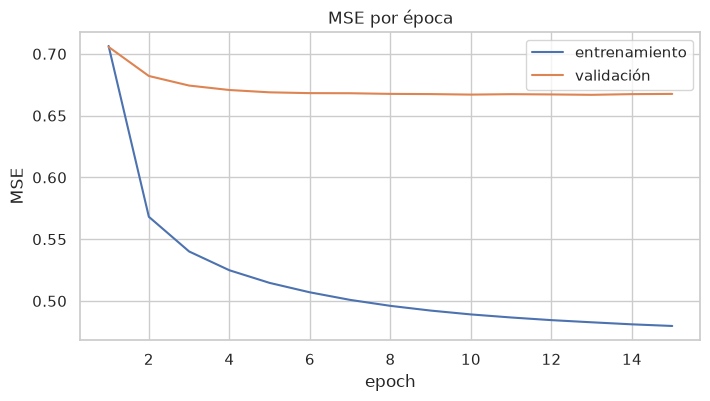

In [4]:
@torch.no_grad()
def evaluate_loss(loader_):
    model.eval(); total_loss = total_n = 0
    predictions, targets = [], []
    for users, items, ratings in loader_:
        users, items, ratings = users.to(device), items.to(device), ratings.to(device)
        pred = model(users, items); total_loss += loss_fn(pred, ratings).item() * len(ratings); total_n += len(ratings)
        predictions.append(pred.cpu()); targets.append(ratings.cpu())
    return total_loss / total_n, rating_metrics(torch.cat(predictions), torch.cat(targets))

history, best_loss, wait = [], float('inf'), 0
checkpoint = ARTIFACTS / 'best_model.pt'
for epoch in range(1, MAX_EPOCHS + 1):
    model.train(); total_loss = total_n = 0
    for users, items, ratings in train_loader:
        users, items, ratings = users.to(device), items.to(device), ratings.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(users, items), ratings); loss.backward(); optimizer.step()
        total_loss += loss.item() * len(ratings); total_n += len(ratings)
    train_mse = total_loss / total_n; valid_mse, valid_metrics = evaluate_loss(valid_loader)
    row = {'epoch': epoch, 'train_mse': train_mse, 'valid_mse': valid_mse, **{f'valid_{k}': v for k, v in valid_metrics.items()}}
    history.append(row); print(row)
    if valid_mse < best_loss - 1e-6:
        best_loss, wait = valid_mse, 0
        torch.save({'state_dict': model.state_dict(), 'epoch': epoch, 'valid_mse': valid_mse}, checkpoint)
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f'Early Stopping en época {epoch}'); break
history_df = pd.DataFrame(history); history_df.to_csv(ARTIFACTS / 'training_history.csv', index=False)
plt.figure(figsize=(8, 4)); sns.lineplot(data=history_df, x='epoch', y='train_mse', label='entrenamiento'); sns.lineplot(data=history_df, x='epoch', y='valid_mse', label='validación')
plt.title('MSE por época'); plt.ylabel('MSE'); plt.savefig(ARTIFACTS / 'loss_curve.png', dpi=160, bbox_inches='tight'); plt.show()


## 4. Evaluación de ratings y baseline
El baseline para rating predice la media global calculada exclusivamente en entrenamiento. El modelo final se restaura desde el mejor checkpoint antes de medir prueba; MAE y RMSE son métricas de predicción de estrellas.

In [5]:
saved = torch.load(checkpoint, map_location=device, weights_only=True)
model.load_state_dict(saved['state_dict'])
test_mse, test_metrics = evaluate_loss(test_loader)
baseline_errors = test.rating.to_numpy() - global_mean
baseline_rating = {'mae': float(np.abs(baseline_errors).mean()), 'rmse': float(np.sqrt(np.mean(baseline_errors ** 2))), 'mse': float(np.mean(baseline_errors ** 2))}
rating_results = pd.DataFrame([{'modelo': 'Media global (train)', **baseline_rating}, {'modelo': 'Factorización matricial', **test_metrics, 'mse': test_mse}])
display(rating_results)


,modelo,mae,rmse,mse
0,Media global (train),0.728927,0.942462,0.888235
1,Factorización matricial,0.664845,0.842457,0.709733


## 5. Ranking Top-K
Un ítem es relevante si el rating de prueba es al menos 4. Para mantener un coste realista, se evalúan hasta 5,000 usuarios relevantes elegidos determinísticamente. Para cada uno, los candidatos son su ítem relevante de prueba más 1,000 libros de entrenamiento no vistos por ese usuario. Se excluyen libros de entrenamiento ya observados; la ausencia de interacción no se etiqueta como negativa, solo se usa como candidato no observado. El baseline ordena candidatos por popularidad de entrenamiento.

In [6]:
def topk_metrics(frame, label):
    relevant = frame[frame.rating >= 4].sort_values('user_idx')
    users = relevant.user_idx.drop_duplicates().to_numpy()
    rng = np.random.default_rng(SEED + (0 if label == 'validación' else 1))
    selected = rng.choice(users, size=min(TOPK_USERS, len(users)), replace=False)
    target = relevant[relevant.user_idx.isin(selected)].drop_duplicates('user_idx').set_index('user_idx').book_idx.to_dict()
    seen = train[train.user_idx.isin(selected)].groupby('user_idx').book_idx.agg(set).to_dict()
    popularity = train.groupby('book_idx').size().reindex(range(len(book_mapping)), fill_value=0).to_numpy()
    catalog = np.arange(len(book_mapping)); rows = []
    model.eval()
    for user in selected:
        allowed = np.setdiff1d(catalog, np.fromiter(seen.get(user, set()), dtype=np.int64), assume_unique=False)
        item = target[user]; pool = allowed[allowed != item]
        negatives = rng.choice(pool, size=min(NEGATIVES, len(pool)), replace=False)
        candidates = np.concatenate(([item], negatives))
        with torch.no_grad():
            scores = model(torch.full((len(candidates),), int(user), device=device), torch.tensor(candidates, device=device)).cpu().numpy()
        for name, values in [('Factorización', scores), ('Popularidad train', popularity[candidates])]:
            rank = int(np.where(candidates[np.argsort(-values)] == item)[0][0]) + 1
            hit = rank <= TOP_K
            rows.append({'partición': label, 'modelo': name, 'usuarios': len(selected), 'precision@k': float(hit / TOP_K), 'recall@k': float(hit), 'ndcg@k': float(1 / np.log2(rank + 1) if hit else 0)})
    return pd.DataFrame(rows).groupby(['partición', 'modelo', 'usuarios'], as_index=False)[['precision@k', 'recall@k', 'ndcg@k']].mean()

ranking_results = pd.concat([topk_metrics(valid, 'validación'), topk_metrics(test, 'prueba')], ignore_index=True)
display(ranking_results)
display(Markdown('**Interpretación.** Los resultados Top-K corresponden al conjunto de candidatos definido arriba; no estiman un ranking sobre todo el catálogo. La validación sirve para detectar configuraciones prometedoras y la fila de prueba permanece como evaluación final del checkpoint seleccionado.'))


,partición,modelo,usuarios,precision@k,recall@k,ndcg@k
0,validación,Factorización,5000,0.01434,0.1434,0.086910
1,validación,Popularidad train,5000,0.04100,0.4100,0.272561
2,prueba,Factorización,5000,0.01402,0.1402,0.084320
3,prueba,Popularidad train,5000,0.03802,0.3802,0.248692


**Interpretación.** Los resultados Top-K corresponden al conjunto de candidatos definido arriba; no estiman un ranking sobre todo el catálogo. La validación sirve para detectar configuraciones prometedoras y la fila de prueba permanece como evaluación final del checkpoint seleccionado.

## 6. Exportación y ejemplo de inferencia
Se guardan checkpoint, configuración, mapeos, historial y métricas. Cargar el `state_dict` es explícito y portable; no se serializa el objeto completo del modelo.

In [7]:
config = {'seed': SEED, 'factors': FACTORS, 'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY, 'batch_size': BATCH_SIZE, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'global_mean': global_mean, 'num_users': len(user_mapping), 'num_items': len(book_mapping), 'relevance_rating': 4, 'top_k': TOP_K, 'topk_candidate_policy': 'relevant_test_item_plus_1000_unseen_train_items'}
(ARTIFACTS / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
metrics = {'rating_test': rating_results.to_dict(orient='records'), 'ranking': ranking_results.to_dict(orient='records'), 'best_epoch': int(saved['epoch']), 'best_valid_mse': float(saved['valid_mse'])}
(ARTIFACTS / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
shutil.copy2(ML / 'user_mapping.parquet', ARTIFACTS / 'user_mapping.parquet'); shutil.copy2(ML / 'book_mapping.parquet', ARTIFACTS / 'book_mapping.parquet')
example_user = int(test.user_idx.iloc[0]); seen_items = set(train.loc[train.user_idx.eq(example_user), 'book_idx'])
candidates = np.setdiff1d(np.arange(len(book_mapping)), np.fromiter(seen_items, dtype=np.int64))
with torch.no_grad(): scores = model(torch.full((len(candidates),), example_user, device=device), torch.tensor(candidates, device=device)).cpu().numpy()
top_items = candidates[np.argsort(-scores)[:10]]
titles = pd.read_parquet(PROCESSED / 'books.parquet')[['book_id', 'title']]
recommendations = pd.DataFrame({'book_id': book_ids_for_indices(book_mapping, top_items)}).merge(titles, on='book_id', how='left')[['book_id', 'title']]
display(recommendations)
display(Markdown(f"Checkpoint restaurado desde época {saved['epoch']}. El ejemplo usa `user_idx={example_user}` y excluye sus libros observados en entrenamiento; para un usuario desconocido se requiere un fallback, no embeddings inexistentes."))


,book_id,title
0,24812,The Complete Calvin and Hobbes
1,29436571,"March: Book Three (March, #3)"
2,22487952,"March: Book Two (March, #2)"
3,54741,Toda Mafalda
4,70487,Attack of the Deranged Mutant Killer Monster S...
5,77730,Weirdos from Another Planet!: A Calvin and Hob...
6,24814,It's a Magical World: A Calvin and Hobbes Coll...
7,24816,Homicidal Psycho Jungle Cat: A Calvin and Hobb...
8,59715,The Authoritative Calvin and Hobbes: A Calvin ...
9,121792,The Revenge of the Baby-Sat


Checkpoint restaurado desde época 13. El ejemplo usa `user_idx=22071` y excluye sus libros observados en entrenamiento; para un usuario desconocido se requiere un fallback, no embeddings inexistentes.